# 73장 · 같은 문서와 벡터로 검색 저장소 비교하기

같은 원문을 같은 벡터로 바꿨는데 한 화면에는 거리가 2, 다른 화면에는 약 1.414가 나옵니다. 문서 순위까지 바뀐 걸까요? 70장의 과제 안내를 소재로 만든 짧은 문장 두 개를 사용해 거리 계산부터 PostgreSQL의 pgvector 검색식까지 따라갑니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 세 칸짜리 벡터 읽기

제공 E1 규칙은 ‘과제’, ‘제출’, ‘검토’가 원문에 들어 있으면 해당 칸을 1로 둡니다. 단어 포함 여부를 보는 수업용 벡터라서 의미가 비슷해도 표현이 다른 단어는 잡지 못합니다.

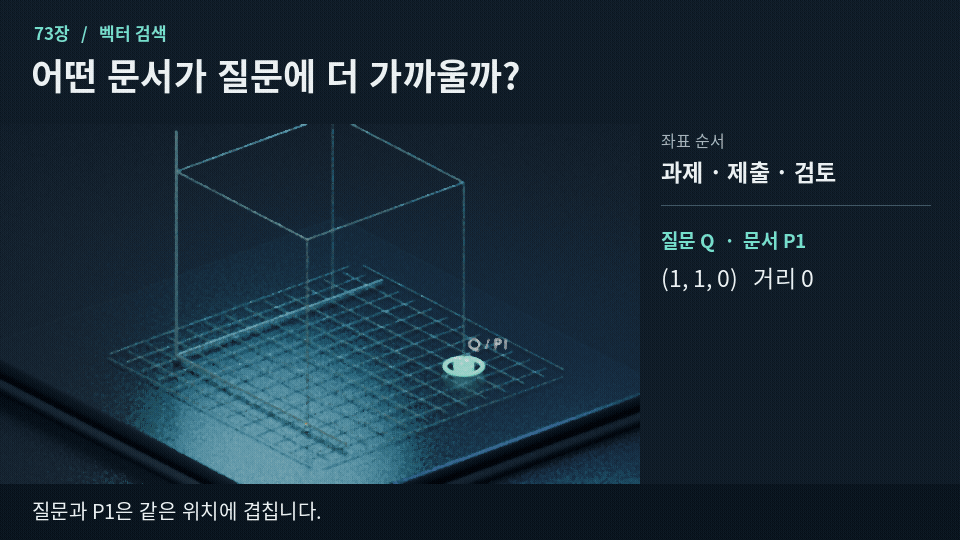

**볼 곳**　민트색 고리는 질문 Q, 그 안의 점은 문서 P1입니다. 주황색 두 선분이 그려진 뒤 흰 대각선이 나타납니다.

**애니메이션의 의미**　질문과 P1은 세 좌표가 모두 같아 거리가 0입니다. P2는 두 좌표에서 한 칸씩 달라 직선거리가 √2입니다. 거리가 작은 P1이 먼저 검색됩니다.

<!-- motion:distance-triangle -->
**좌표 두 칸이 다르면 거리는 왜 1.414일까요?**

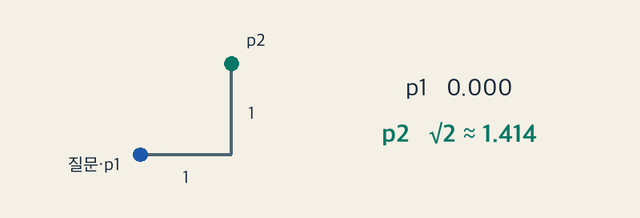

p1은 질문과 같은 점이라 거리가 0입니다. p2는 두 축에서 각각 1만큼 달라 직각삼각형의 빗변 길이 √2만큼 떨어져 있습니다.
<!-- /motion -->


### 셀 01 · 질문과 두 문서의 거리 구하기

검색 질문과 두 문서에 같은 규칙을 적용합니다. 질문과 거리가 가까운 문서부터 정렬합니다.

p2에서 다른 좌표가 두 개이고 각 차이의 크기가 1이면 제곱합은 1²+1²=2입니다. L2 거리는 여기에 제곱근을 취한 약 1.414입니다. 같은 벡터라도 거리와 거리의 제곱은 숫자가 다릅니다.

In [1]:
from math import dist
terms = ["과제", "제출", "검토"]
def embed(text):
    return [float(word in text) for word in terms]

query = embed("과제 제출")
texts = {"p1": "과제 제출 장소는 과제함입니다.", "p2": "과제 검토 기준을 읽으세요."}
ranked = sorted((dist(query, embed(text)), key) for key, text in texts.items())
print([(key, round(distance, 3)) for distance, key in ranked])

[('p1', 0.0), ('p2', 1.414)]


p1은 세 칸 모두 질문과 같아서 거리가 0입니다. p2는 제출과 검토 두 칸이 달라 L2 거리가 √2입니다. 거리를 제곱하면 2가 되지만 순서는 같습니다.

### 과제 02 · 질문의 단어 하나 바꾸기

질문을 ‘과제 검토’로 바꿔 가장 가까운 청크의 키를 구하세요.

In [2]:
# query와 같은 embed, dist를 사용하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>new_query = embed(&#x27;과제 검토&#x27;)
print(min(texts, key=lambda key: dist(new_query, embed(texts[key]))))</code></pre>
<p>실행 결과</p><pre><code>p2</code></pre>
<p>p2가 가장 가깝습니다. 벡터의 차원을 바꾸거나 단어 순서를 다르게 하면 이 결과를 기존 인덱스와 직접 비교할 수 없습니다.</p>
</details>

## 동일 벡터를 pgvector에서 조회하기

PostgreSQL에서 vector(3) 열은 세 값을 받습니다. <-> 연산자는 L2 거리를 반환하므로 작은 순서대로 정렬합니다. 실제 서비스는 여기에 소유자·허용 문서 범위를 걸고 청크 ID로 원문 표를 연결합니다.


### 셀 03 · 선택 실습 · 준비된 PostgreSQL에서 검색

강사가 읽기 가능한 pgvector 수업 DB를 준비했으면 run_postgres를 켭니다. 연결 설정은 수업 커널의 표준 PG 환경변수를 사용합니다. 아래 SELECT는 제공한 두 벡터만 계산하며 테이블을 변경하지 않습니다.

In [3]:
run_postgres = False
sql = """WITH docs(id, embedding) AS (
  VALUES ('p1', '[1,1,0]'::vector(3)), ('p2', '[1,0,1]'::vector(3))
) SELECT id, embedding <-> %s::vector AS raw_l2
FROM docs ORDER BY raw_l2, id"""
if run_postgres:
    import psycopg
    with psycopg.connect(connect_timeout=3) as pg:
        rows = pg.execute(sql, ("[1,1,0]",)).fetchall()
        print([(key, round(distance, 3)) for key, distance in rows])
else:
    print("PostgreSQL 연결을 선택하지 않았습니다.")

PostgreSQL 연결을 선택하지 않았습니다.


기본 실행에서는 PostgreSQL을 호출하지 않습니다. 실제 DB에서 비교할 때는 p1의 0과 p2의 약 1.414, 이어서 두 ID의 순서를 앞 셀과 맞춰 보세요. 수업용 DB에 vector 확장이 있고 커널에서 psycopg로 접속할 수 있을 때 run_postgres를 True로 바꾸세요. p1, p2 순서와 두 거리 값을 Python 결과 옆에 적으세요.

## 돌아보기

벡터 규칙이나 임베딩 모델을 교체했다면 기존 DB 행과 같은 좌표계인지 먼저 확인하세요. 차원 수만 같다고 이전 인덱스를 그대로 쓸 수 있는 것은 아닙니다.